# Лабораторная работа №5 — вариант 7

In [1]:
import math
import random
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import MCXGate
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.compiler import transpile


def state_basis_index(circuit):
    state = Statevector.from_instruction(circuit)
    probabilities = np.abs(state.data) ** 2
    index = int(np.argmax(probabilities))
    assert np.isclose(probabilities[index], 1.0)
    return index


def qbit(index, bit):
    return (index >> bit) & 1


def gate_counts(circuit):
    operations = circuit.count_ops()
    return {
        "qubits": circuit.num_qubits,
        "CX": operations.get("cx", 0),
        "CCX": operations.get("ccx", 0),
        "depth": circuit.depth(),
    }


def print_table(headers, rows):
    widths = [
        max(len(str(header)), *(len(str(row[i])) for row in rows))
        for i, header in enumerate(headers)
    ]
    print(" | ".join(str(value).ljust(widths[i]) for i, value in enumerate(headers)))
    print("-+-".join("-" * width for width in widths))
    for row in rows:
        print(" | ".join(str(value).ljust(widths[i]) for i, value in enumerate(row)))




## Задание 1. Полный сумматор и сумматор с цепочкой переноса

Для заданных входов таблица истинности даёт `S=0`, `C=1`.
В цепочке переноса промежуточные биты переноса сохраняются в отдельных
кубитах; все проверки выполняются программно через `assert`.



In [2]:
def build_full_adder(input_bits=None, measured=False):
    if measured:
        circuit = QuantumCircuit(5, 2)
    else:
        circuit = QuantumCircuit(5)
    if input_bits is not None:
        for index, value in enumerate(input_bits):
            if value:
                circuit.x(index)

    a, b, carry_in, total, carry_out = range(5)
    circuit.cx(a, total)
    circuit.cx(b, total)
    circuit.cx(carry_in, total)
    circuit.ccx(a, b, carry_out)
    circuit.ccx(a, carry_in, carry_out)
    circuit.ccx(b, carry_in, carry_out)
    if measured:
        circuit.measure(total, 0)
        circuit.measure(carry_out, 1)
    return circuit


full_adder_state = build_full_adder((1, 0, 1))
state_index = state_basis_index(full_adder_state)
sum_bit, carry_bit = qbit(state_index, 3), qbit(state_index, 4)
assert (sum_bit, carry_bit) == (0, 1)
print("A=1, B=0, X=1 -> S={}, C={}".format(sum_bit, carry_bit))

counts = AerSimulator().run(
    build_full_adder((1, 0, 1), measured=True),
    shots=1024,
    seed_simulator=2026,
).result().get_counts()
print("Измерения (1024 shots):", counts)

full_adder_rows = []
for a, b, carry_in in product((0, 1), repeat=3):
    circuit = build_full_adder((a, b, carry_in))
    result_index = state_basis_index(circuit)
    actual_sum = qbit(result_index, 3)
    actual_carry = qbit(result_index, 4)
    expected_sum = a ^ b ^ carry_in
    expected_carry = int((a + b + carry_in) >= 2)
    assert (actual_sum, actual_carry) == (expected_sum, expected_carry)
    full_adder_rows.append(
        (a, b, carry_in, expected_sum, expected_carry, actual_sum, actual_carry)
    )
print_table(("A", "B", "X", "S ожид.", "C ожид.", "S схема", "C схема"), full_adder_rows)


def apply_not(circuit, target):
    circuit.x(target)


def apply_and(circuit, left, right, target):
    circuit.ccx(left, right, target)


def apply_xor(circuit, left, right, target):
    circuit.cx(left, target)
    circuit.cx(right, target)


def apply_or(circuit, left, right, target):
    apply_xor(circuit, left, right, target)
    apply_and(circuit, left, right, target)


def apply_nand(circuit, left, right, target):
    apply_and(circuit, left, right, target)
    apply_not(circuit, target)


def apply_nor(circuit, left, right, target):
    circuit.x(left)
    circuit.x(right)
    apply_and(circuit, left, right, target)
    circuit.x(right)
    circuit.x(left)


def apply_majority(circuit, first, second, third, target):
    apply_and(circuit, first, second, target)
    apply_and(circuit, first, third, target)
    apply_and(circuit, second, third, target)


def check_primitive(apply_gate, input_width, expected_function):
    for values in product((0, 1), repeat=input_width):
        circuit = QuantumCircuit(input_width + 1)
        for index, value in enumerate(values):
            if value:
                circuit.x(index)
        apply_gate(circuit, input_width)
        result = state_basis_index(circuit)
        assert tuple(qbit(result, i) for i in range(input_width)) == values
        assert qbit(result, input_width) == expected_function(*values)


check_primitive(
    lambda circuit, target: apply_and(circuit, 0, 1, target),
    2,
    lambda a, b: a & b,
)
check_primitive(
    lambda circuit, target: apply_or(circuit, 0, 1, target),
    2,
    lambda a, b: a | b,
)
check_primitive(
    lambda circuit, target: apply_xor(circuit, 0, 1, target),
    2,
    lambda a, b: a ^ b,
)
check_primitive(
    lambda circuit, target: apply_nand(circuit, 0, 1, target),
    2,
    lambda a, b: 1 - (a & b),
)
check_primitive(
    lambda circuit, target: apply_nor(circuit, 0, 1, target),
    2,
    lambda a, b: 1 - (a | b),
)
check_primitive(
    lambda circuit, target: apply_majority(circuit, 0, 1, 2, target),
    3,
    lambda a, b, c: int(a + b + c >= 2),
)
not_circuit = QuantumCircuit(1)
apply_not(not_circuit, 0)
assert state_basis_index(not_circuit) == 1
print("Базовые логические элементы проверены на всех входах.")


def build_full_adder_two_half_adders(input_bits=None):
    circuit = QuantumCircuit(8)
    if input_bits is not None:
        for index, value in enumerate(input_bits):
            if value:
                circuit.x(index)

    a, b, carry_in, total, carry_out, partial_sum, carry_ab, carry_partial = range(8)
    circuit.cx(a, partial_sum)
    circuit.cx(b, partial_sum)
    circuit.cx(partial_sum, total)
    circuit.cx(carry_in, total)
    circuit.ccx(a, b, carry_ab)
    circuit.ccx(partial_sum, carry_in, carry_partial)
    apply_or(circuit, carry_ab, carry_partial, carry_out)
    circuit.ccx(partial_sum, carry_in, carry_partial)
    circuit.ccx(a, b, carry_ab)
    circuit.cx(b, partial_sum)
    circuit.cx(a, partial_sum)
    return circuit


half_adder_rows = []
for a, b, carry_in in product((0, 1), repeat=3):
    index = state_basis_index(build_full_adder_two_half_adders((a, b, carry_in)))
    actual = (qbit(index, 3), qbit(index, 4))
    expected = (a ^ b ^ carry_in, int(a + b + carry_in >= 2))
    assert actual == expected
    half_adder_rows.append((a, b, carry_in, expected[0], expected[1], *actual))
print("Проверка реализации из двух полусумматоров:")
print_table(("A", "B", "X", "S ожид.", "C ожид.", "S схема", "C схема"), half_adder_rows)
print("Прямая реализация:", gate_counts(build_full_adder()))
print("Два полусумматора:", gate_counts(build_full_adder_two_half_adders()))


def build_ripple_adder(width):
    if width < 1:
        raise ValueError("Разрядность должна быть положительной")
    circuit = QuantumCircuit(4 * width)
    a_start = 0
    b_start = width
    sum_start = 2 * width
    carry_start = 3 * width

    circuit.cx(a_start, sum_start)
    circuit.cx(b_start, sum_start)
    circuit.ccx(a_start, b_start, carry_start)
    for bit in range(1, width):
        a = a_start + bit
        b = b_start + bit
        carry_in = carry_start + bit - 1
        total = sum_start + bit
        carry_out = carry_start + bit
        circuit.cx(a, total)
        circuit.cx(b, total)
        circuit.cx(carry_in, total)
        circuit.ccx(a, b, carry_out)
        circuit.ccx(a, carry_in, carry_out)
        circuit.ccx(b, carry_in, carry_out)
    return circuit


adder_size_rows = []
for width in (2, 3, 4):
    circuit = build_ripple_adder(width)
    for a in range(1 << width):
        for b in range(1 << width):
            initial_index = a | (b << width)
            final_index = Statevector.from_int(
                initial_index, dims=1 << circuit.num_qubits
            ).evolve(circuit)
            basis_index = int(np.argmax(np.abs(final_index.data) ** 2))
            measured_sum = sum(
                qbit(basis_index, 2 * width + bit) << bit for bit in range(width)
            )
            measured_sum |= qbit(basis_index, 4 * width - 1) << width
            assert measured_sum == a + b
    adder_size_rows.append((width, *gate_counts(circuit).values()))
print("Проверены все входные пары; ресурсные показатели:")
print_table(("Разрядность", "Кубиты", "CX", "CCX", "Глубина"), adder_size_rows)




A=1, B=0, X=1 -> S=0, C=1
Измерения (1024 shots): {'10': 1024}
A | B | X | S ожид. | C ожид. | S схема | C схема
--+---+---+---------+---------+---------+--------
0 | 0 | 0 | 0       | 0       | 0       | 0      
0 | 0 | 1 | 1       | 0       | 1       | 0      
0 | 1 | 0 | 1       | 0       | 1       | 0      
0 | 1 | 1 | 0       | 1       | 0       | 1      
1 | 0 | 0 | 1       | 0       | 1       | 0      
1 | 0 | 1 | 0       | 1       | 0       | 1      
1 | 1 | 0 | 0       | 1       | 0       | 1      
1 | 1 | 1 | 1       | 1       | 1       | 1      
Базовые логические элементы проверены на всех входах.
Проверка реализации из двух полусумматоров:
A | B | X | S ожид. | C ожид. | S схема | C схема
--+---+---+---------+---------+---------+--------
0 | 0 | 0 | 0       | 0       | 0       | 0      
0 | 0 | 1 | 1       | 0       | 1       | 0      
0 | 1 | 0 | 1       | 0       | 1       | 0      
0 | 1 | 1 | 0       | 1       | 0       | 1      
1 | 0 | 0 | 1       | 0       | 1      

**Ответы на вопросы задания 1.**

Перенос полного сумматора равен `AB OR AX OR BX`: один CCX формирует только
одно произведение двух входов, поэтому для всей функции нужны все три
слагаемых. CX копирует классический бит в вычислительном базисе, но для
суперпозиции он создаёт запутанное состояние, а не две независимые копии;
это согласуется с запретом клонирования. Глубину цепочного сумматора можно
уменьшить параллельным вычислением переносов, но для этого потребуются
дополнительные промежуточные кубиты и вентили.

Для заданного входа правильный результат `S=0, C=1`. Прямая схема требует
меньше кубитов, CX, CCX и имеет меньшую глубину, чем реализация из двух
полусумматоров с вычислением ИЛИ. Глубины сумматоров на 2, 3 и 4 бита
равны 6, 9 и 12, то есть в этой цепочной схеме растут линейно.



## Задание 2. Булева функция

`F(A,B,C,D) = (A AND B) OR (C AND D) OR (A AND C)`.
Входы остаются неизменными. Вспомогательные кубиты очищаются обратным
вычислением; обе схемы сверяются с классической функцией на всех 16 входах.



In [3]:
def function_variant_7(a, b, c, d):
    return int((a and b) or (c and d) or (a and c))


def build_function_circuit(optimized=False):
    if optimized:
        circuit = QuantumCircuit(8)
        compute = QuantumCircuit(8)
        a, b, c, d, output, ab, a_or_d, term = range(8)
        apply_and(compute, a, b, ab)
        apply_or(compute, a, d, a_or_d)
        apply_and(compute, c, a_or_d, term)
        circuit.compose(compute, inplace=True)
        apply_or(circuit, ab, term, output)
        circuit.compose(compute.inverse(), inplace=True)
    else:
        circuit = QuantumCircuit(9)
        compute = QuantumCircuit(9)
        a, b, c, d, output, ab, cd, ac, ab_or_cd = range(9)
        apply_and(compute, a, b, ab)
        apply_and(compute, c, d, cd)
        apply_and(compute, a, c, ac)
        apply_or(compute, ab, cd, ab_or_cd)
        circuit.compose(compute, inplace=True)
        apply_or(circuit, ab_or_cd, ac, output)
        circuit.compose(compute.inverse(), inplace=True)
    return circuit


def prepare_boolean_test(circuit, input_bits):
    measured = QuantumCircuit(circuit.num_qubits)
    for index, value in enumerate(input_bits):
        if value:
            measured.x(index)
    measured.compose(circuit, inplace=True)
    measured.add_register(ClassicalRegister(measured.num_qubits))
    measured.measure(range(measured.num_qubits), range(measured.num_qubits))
    return measured


def check_boolean_implementation(optimized, shots=100):
    base = build_function_circuit(optimized=optimized)
    inputs = list(product((0, 1), repeat=4))
    circuits = [prepare_boolean_test(base, bits) for bits in inputs]
    results = AerSimulator().run(circuits, shots=shots, seed_simulator=2026).result()
    rows = []
    for bits, circuit_index in zip(inputs, range(len(inputs))):
        expected = function_variant_7(*bits)
        for key, count in results.get_counts(circuit_index).items():
            measured = key.replace(" ", "")[::-1]
            assert int(measured[4]) == expected
            assert all(bit == "0" for bit in measured[5:])
            assert count == shots
        state_index = state_basis_index(
            prepare_boolean_state(base, bits)
        )
        assert qbit(state_index, 4) == expected
        rows.append(("".join(map(str, bits)), expected, expected, "OK"))
    return base, rows


def prepare_boolean_state(circuit, input_bits):
    prepared = QuantumCircuit(circuit.num_qubits)
    for index, value in enumerate(input_bits):
        if value:
            prepared.x(index)
    prepared.compose(circuit, inplace=True)
    return prepared


base_function, base_rows = check_boolean_implementation(optimized=False)
optimized_function, optimized_rows = check_boolean_implementation(optimized=True)
print("Базовая схема:")
print_table(("ABCD", "F класс.", "F квант.", "Проверка"), base_rows)
print("Оптимизированная схема:")
print_table(("ABCD", "F класс.", "F квант.", "Проверка"), optimized_rows)
print("Ресурсы базовой схемы:", gate_counts(base_function))
print("Ресурсы оптимизированной схемы:", gate_counts(optimized_function))



Базовая схема:
ABCD | F класс. | F квант. | Проверка
-----+----------+----------+---------
0000 | 0        | 0        | OK      
0001 | 0        | 0        | OK      
0010 | 0        | 0        | OK      
0011 | 1        | 1        | OK      
0100 | 0        | 0        | OK      
0101 | 0        | 0        | OK      
0110 | 0        | 0        | OK      
0111 | 1        | 1        | OK      
1000 | 0        | 0        | OK      
1001 | 0        | 0        | OK      
1010 | 1        | 1        | OK      
1011 | 1        | 1        | OK      
1100 | 1        | 1        | OK      
1101 | 1        | 1        | OK      
1110 | 1        | 1        | OK      
1111 | 1        | 1        | OK      
Оптимизированная схема:
ABCD | F класс. | F квант. | Проверка
-----+----------+----------+---------
0000 | 0        | 0        | OK      
0001 | 0        | 0        | OK      
0010 | 0        | 0        | OK      
0011 | 1        | 1        | OK      
0100 | 0        | 0        | OK      
0101 | 0   

Оптимизированная схема использует на один вспомогательный кубит и на два
CCX меньше, но её глубина на единицу больше. Минимизация числа кубитов и
вентилей поэтому не обязана одновременно минимизировать глубину.




## Задание 3. Деполяризующий шум

Для обеих реализаций применяются `p1=0.001` и заданные значения `p2`.
Схемы предварительно раскладываются в базис `u, cx`; сравнивается доля
правильных ответов по всем 16 наборам входов.



p2    | Базовая, доля верных | Оптимизированная, доля верных
------+----------------------+------------------------------
0     | 0.98748779296875     | 0.9923095703125              
0.001 | 0.97991943359375     | 0.98443603515625             
0.005 | 0.9447021484375      | 0.9581298828125              
0.01  | 0.9034423828125      | 0.92510986328125             
0.02  | 0.83148193359375     | 0.8681640625                 


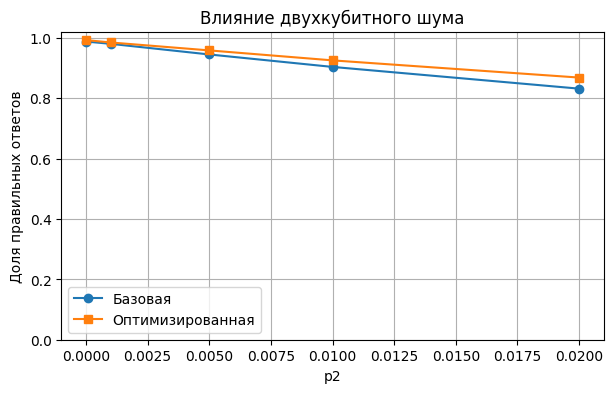

In [4]:
def make_noise_model(p1, p2):
    noise = NoiseModel()
    noise.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["u"])
    noise.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    return noise


def noisy_function_accuracy(base, p1, p2, shots=1024):
    circuits = [
        prepare_boolean_test(base, bits)
        for bits in product((0, 1), repeat=4)
    ]
    transpiled = transpile(circuits, basis_gates=["u", "cx"], optimization_level=0)
    assert all("ccx" not in circuit.count_ops() for circuit in transpiled)
    simulator = AerSimulator(noise_model=make_noise_model(p1, p2))
    results = simulator.run(
        transpiled, shots=shots, seed_simulator=2026
    ).result()
    correct = 0
    total = 16 * shots
    for index, bits in enumerate(product((0, 1), repeat=4)):
        expected = function_variant_7(*bits)
        for key, count in results.get_counts(index).items():
            measured = key.replace(" ", "")[::-1]
            if int(measured[4]) == expected:
                correct += count
    return correct / total


p2_values = (0, 0.001, 0.005, 0.01, 0.02)
noise_results = {"базовая": [], "оптимизированная": []}
for p2 in p2_values:
    noise_results["базовая"].append(
        noisy_function_accuracy(base_function, 0.001, p2)
    )
    noise_results["оптимизированная"].append(
        noisy_function_accuracy(optimized_function, 0.001, p2)
    )
print_table(
    ("p2", "Базовая, доля верных", "Оптимизированная, доля верных"),
    [
        (p2, noise_results["базовая"][i], noise_results["оптимизированная"][i])
        for i, p2 in enumerate(p2_values)
    ],
)
plt.figure(figsize=(7, 4))
plt.plot(p2_values, noise_results["базовая"], "o-", label="Базовая")
plt.plot(p2_values, noise_results["оптимизированная"], "s-", label="Оптимизированная")
plt.xlabel("p2")
plt.ylabel("Доля правильных ответов")
plt.ylim(0, 1.02)
plt.grid(True)
plt.legend()
plt.title("Влияние двухкубитного шума")
plt.show()



При росте `p2` доля правильных ответов падает, поскольку ошибки CX
накапливаются в схеме. В этой проверке оптимизированная схема устойчивее:
у неё меньше CCX до разложения, а при заданной транспиляции — меньше
затрагиваемых шумом операций.




## Задание 4. Оракул, диффузор и проверка алгоритма Гровера

Строка состояния записывается в обычном двоичном порядке, а индекс кубита
в Qiskit — справа налево. Матрицы оракула и диффузора проверяются напрямую.



In [5]:
def validate_marked(n, marked):
    if n < 1 or len(marked) != n or any(bit not in "01" for bit in marked):
        raise ValueError("marked должна быть двоичной строкой длины n")


def phase_flip_all_ones(circuit, n):
    if n == 1:
        circuit.z(0)
    else:
        target = n - 1
        circuit.h(target)
        circuit.append(MCXGate(n - 1), list(range(n)))
        circuit.h(target)


def build_oracle(n, marked):
    validate_marked(n, marked)
    circuit = QuantumCircuit(n)
    for qubit, bit in enumerate(reversed(marked)):
        if bit == "0":
            circuit.x(qubit)
    phase_flip_all_ones(circuit, n)
    for qubit, bit in enumerate(reversed(marked)):
        if bit == "0":
            circuit.x(qubit)
    return circuit


def build_oracle_set(n, marked_states):
    if isinstance(marked_states, str):
        marked_states = [marked_states]
    circuit = QuantumCircuit(n)
    for marked in marked_states:
        circuit.compose(build_oracle(n, marked), inplace=True)
    return circuit


def build_diffuser(n):
    if n < 1:
        raise ValueError("n должно быть положительным")
    circuit = QuantumCircuit(n)
    circuit.h(range(n))
    circuit.x(range(n))
    phase_flip_all_ones(circuit, n)
    circuit.x(range(n))
    circuit.h(range(n))
    return circuit


for n in (2, 3, 4, 5):
    marked = format((1 << n) - 2, "0{}b".format(n))
    oracle = Operator(build_oracle(n, marked)).data
    expected_diagonal = np.ones(1 << n, dtype=complex)
    expected_diagonal[int(marked, 2)] = -1
    assert np.allclose(oracle, np.diag(expected_diagonal))
    for value in range(1 << n):
        basis = Statevector.from_int(value, dims=1 << n)
        result = basis.evolve(build_oracle(n, marked))
        expected_phase = -1 if value == int(marked, 2) else 1
        assert np.allclose(result.data[value], expected_phase)

diffuser_checks = []
for n in (2, 3, 4, 5):
    matrix = Operator(build_diffuser(n)).data
    uniform = np.ones(1 << n, dtype=complex) / math.sqrt(1 << n)
    expected = 2 * np.outer(uniform, uniform.conj()) - np.eye(1 << n)
    equal = np.allclose(matrix, expected)
    opposite = np.allclose(matrix, -expected)
    assert equal or opposite
    diffuser_checks.append((n, "совпадает" if equal else "совпадает с общим знаком минус"))
print_table(("n", "Сравнение с 2|s><s|-I"), diffuser_checks)


def build_grover_circuit(n, marked_states, iterations, measured=False):
    circuit = QuantumCircuit(n)
    circuit.h(range(n))
    oracle = build_oracle_set(n, marked_states)
    diffuser = build_diffuser(n)
    for _ in range(iterations):
        circuit.compose(oracle, inplace=True)
        circuit.compose(diffuser, inplace=True)
    if measured:
        circuit.add_register(ClassicalRegister(n))
        circuit.measure(range(n), range(n))
    return circuit


def exact_marked_probability(n, marked_states, iterations):
    if isinstance(marked_states, str):
        marked_states = [marked_states]
    state = Statevector.from_instruction(
        build_grover_circuit(n, marked_states, iterations)
    )
    return sum(
        abs(state.data[int(marked, 2)]) ** 2 for marked in marked_states
    )


def theoretical_probability(n, marked_count, iterations):
    theta = math.asin(math.sqrt(marked_count / (1 << n)))
    return math.sin((2 * iterations + 1) * theta) ** 2


grover_check_rows = []
for iterations in (1, 2):
    actual = exact_marked_probability(3, "101", iterations)
    expected = theoretical_probability(3, 1, iterations)
    assert np.isclose(actual, expected)
    grover_check_rows.append((iterations, actual, expected))
print_table(("k", "P по Statevector", "P по формуле"), grover_check_rows)



n | Сравнение с 2|s><s|-I         
--+-------------------------------
2 | совпадает с общим знаком минус
3 | совпадает с общим знаком минус
4 | совпадает с общим знаком минус
5 | совпадает с общим знаком минус
k | P по Statevector   | P по формуле      
--+--------------------+-------------------
1 | 0.7812499999999983 | 0.7812500000000001
2 | 0.945312499999996  | 0.9453124999999999


После преобразования `H X ... X H` фазовая инверсия на `|11...1>` становится
инверсией относительно `|00...0>` с общим знаком минус относительно
`2|s><s|-I`. Общая фаза умножает все амплитуды одинаково и не меняет
вероятности измерений.




## Задание 5. Одно отмеченное состояние из 7 кубитов

Для `|1010011>` получаются точные и экспериментальные вероятности при
`k=0..15`. Экспериментальные значения основаны на 1024 измерениях.



Точный оптимум: 8
Экспериментальный оптимум: 8
round(pi/4 * sqrt(N)): 9
floor(pi/4 * sqrt(N)): 8
P по формуле для этих оценок: 0.9877786386137216 0.9956198656943223
Приближённая выборка на каждое k для различения двух лучших вероятностей по нормальной оценке 95%: 1027
Shots | Доля запусков с теоретическим оптимумом
------+----------------------------------------
16    | 0.4                                    
64    | 0.75                                   
256   | 0.75                                   
1024  | 1.0                                    


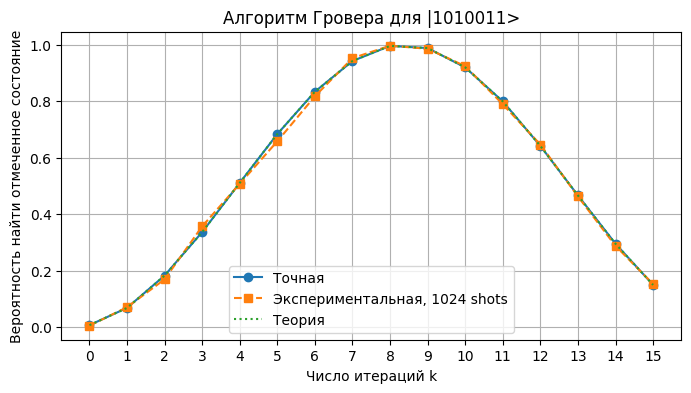

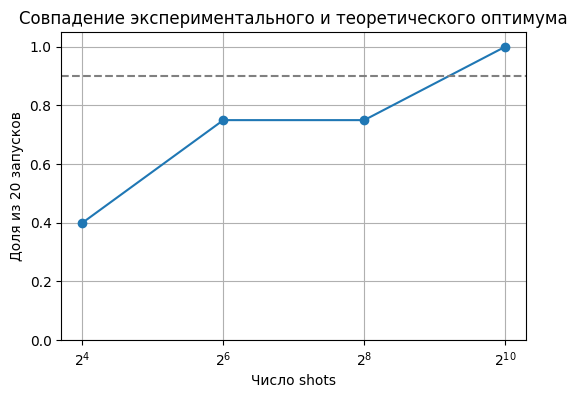

In [6]:
marked_7q = "1010011"
n_7q = len(marked_7q)
k_values = list(range(16))
exact_7q = [
    exact_marked_probability(n_7q, marked_7q, k) for k in k_values
]
theory_7q = [
    theoretical_probability(n_7q, 1, k) for k in k_values
]
assert np.allclose(exact_7q, theory_7q, atol=1e-10)

measured_circuits = [
    build_grover_circuit(n_7q, marked_7q, k, measured=True)
    for k in k_values
]
measured_result = AerSimulator().run(
    measured_circuits, shots=1024, seed_simulator=2026
).result()
experimental_7q = [
    measured_result.get_counts(k).get(marked_7q, 0) / 1024
    for k in k_values
]

plt.figure(figsize=(8, 4))
plt.plot(k_values, exact_7q, "o-", label="Точная")
plt.plot(k_values, experimental_7q, "s--", label="Экспериментальная, 1024 shots")
plt.plot(k_values, theory_7q, ":", label="Теория")
plt.xlabel("Число итераций k")
plt.ylabel("Вероятность найти отмеченное состояние")
plt.xticks(k_values)
plt.grid(True)
plt.legend()
plt.title("Алгоритм Гровера для |1010011>")
plt.show()

exact_optimum_7q = max(k_values, key=exact_7q.__getitem__)
experimental_optimum_7q = max(k_values, key=experimental_7q.__getitem__)
rounded_estimate = round(math.pi / 4 * math.sqrt(1 << n_7q))
floored_estimate = math.floor(math.pi / 4 * math.sqrt(1 << n_7q))
print("Точный оптимум:", exact_optimum_7q)
print("Экспериментальный оптимум:", experimental_optimum_7q)
print("round(pi/4 * sqrt(N)):", rounded_estimate)
print("floor(pi/4 * sqrt(N)):", floored_estimate)
print("P по формуле для этих оценок:",
      theory_7q[rounded_estimate], theory_7q[floored_estimate])

top_two = sorted(k_values, key=exact_7q.__getitem__, reverse=True)[:2]
p_first, p_second = (exact_7q[k] for k in top_two)
z_95 = 1.96
shots_for_95 = math.ceil(
    z_95**2
    * (p_first * (1 - p_first) + p_second * (1 - p_second))
    / (p_first - p_second) ** 2
)
print(
    "Приближённая выборка на каждое k для различения двух лучших "
    "вероятностей по нормальной оценке 95%:",
    shots_for_95,
)

seed_success_rates = []
simulator = AerSimulator()
for shots in (16, 64, 256, 1024):
    successes = 0
    for run in range(20):
        result = simulator.run(
            measured_circuits,
            shots=shots,
            seed_simulator=2026 + run,
        ).result()
        samples = [
            result.get_counts(k).get(marked_7q, 0) / shots for k in k_values
        ]
        if int(np.argmax(samples)) == exact_optimum_7q:
            successes += 1
    seed_success_rates.append(successes / 20)
print_table(
    ("Shots", "Доля запусков с теоретическим оптимумом"),
    list(zip((16, 64, 256, 1024), seed_success_rates)),
)
plt.figure(figsize=(6, 4))
plt.plot((16, 64, 256, 1024), seed_success_rates, "o-")
plt.axhline(0.9, color="gray", linestyle="--")
plt.xscale("log", base=2)
plt.xticks((16, 64, 256, 1024))
plt.xlabel("Число shots")
plt.ylabel("Доля из 20 запусков")
plt.ylim(0, 1.05)
plt.grid(True)
plt.title("Совпадение экспериментального и теоретического оптимума")
plt.show()



Для `N=128` точный дискретный максимум находится при `k=8`; он совпадает
с `floor(pi/4*sqrt(N))`, а округление к ближайшему целому даёт `k=9`.
Выборка может сдвинуть наблюдаемый максимум из-за случайных флуктуаций
измерений. В этих запусках доля достигает 90% при 1024 shots; при 256 shots
она составляет 75%.
Каждая повторная серия запускается в AerSimulator с отдельным seed.

Приближённый расчёт размера выборки использует сравнение двух лучших
вероятностей и нормальную оценку для 95% доверительного уровня; это оценка,
а не гарантия совпадения максимума в каждом отдельном запуске.




## Задание 6. Несколько отмеченных состояний при N=64

Наборы состояний выбираются без повторов с фиксированным seed. Для каждого
`M` строится `P(k)`, находится первый локальный максимум и сравнивается
с теоретической оценкой.



M | floor(pi/4*sqrt(N/M)) | Первый локальный максимум | P                  | Глобальный k
--+-----------------------+---------------------------+--------------------+-------------
1 | 6                     | 6                         | 0.9965856807867882 | 6           
2 | 4                     | 4                         | 0.999182315543286  | 4           
3 | 3                     | 3                         | 0.9981388254091081 | 3           
4 | 3                     | 3                         | 0.9613189697265542 | 15          
8 | 2                     | 2                         | 0.9453124999999966 | 6           
Отмеченные состояния (seed=2026): {1: ['001111'], 2: ['101000', '001101'], 3: ['011100', '110101', '111110'], 4: ['111000', '011110', '000000', '001010'], 8: ['001110', '010010', '110100', '000110', '011100', '000000', '111101', '101011']}
Пример, где глобальный максимум отличается от первого локального: (4, 3, 15)
M  | Оптимальные k на 0..15                          

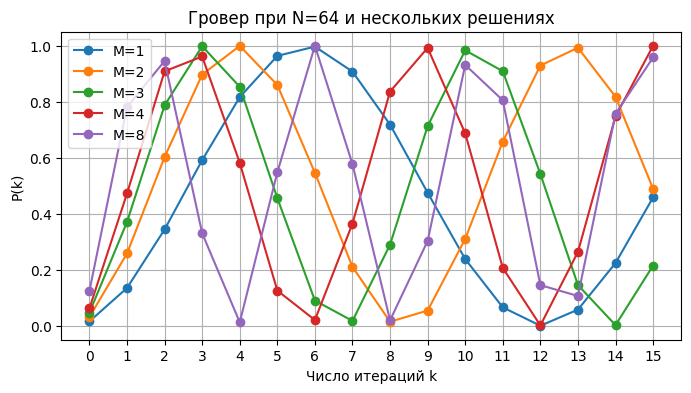

In [7]:
n_multi = 6
random_generator = random.Random(2026)
multi_rows = []
multi_curves = {}
multi_marked_sets = {}
for marked_count in (1, 2, 3, 4, 8):
    marked_values = random_generator.sample(range(1 << n_multi), marked_count)
    marked_states = [
        format(value, "0{}b".format(n_multi)) for value in marked_values
    ]
    multi_marked_sets[marked_count] = marked_states
    curve = [
        exact_marked_probability(n_multi, marked_states, k)
        for k in k_values
    ]
    local_maxima = [
        k
        for k in k_values
        if (k == 0 or curve[k] >= curve[k - 1])
        and (k == 15 or curve[k] >= curve[k + 1])
        and (
            (k > 0 and curve[k] > curve[k - 1])
            or (k < 15 and curve[k] > curve[k + 1])
        )
    ]
    first_local = local_maxima[0]
    global_max = max(k_values, key=curve.__getitem__)
    theoretical = math.floor(
        math.pi / 4 * math.sqrt((1 << n_multi) / marked_count)
    )
    multi_curves[marked_count] = curve
    multi_rows.append(
        (
            marked_count,
            theoretical,
            first_local,
            curve[first_local],
            global_max,
        )
    )

print_table(
    ("M", "floor(pi/4*sqrt(N/M))", "Первый локальный максимум", "P", "Глобальный k"),
    multi_rows,
)
print("Отмеченные состояния (seed=2026):", multi_marked_sets)

plt.figure(figsize=(8, 4))
for marked_count, curve in multi_curves.items():
    plt.plot(k_values, curve, marker="o", label="M={}".format(marked_count))
plt.xlabel("Число итераций k")
plt.ylabel("P(k)")
plt.xticks(k_values)
plt.grid(True)
plt.legend()
plt.title("Гровер при N=64 и нескольких решениях")
plt.show()

different_peaks = [
    (row[0], row[2], row[4])
    for row in multi_rows
    if row[2] != row[4]
]
assert different_peaks
print("Пример, где глобальный максимум отличается от первого локального:",
      different_peaks[0])

large_solution_rows = []
for marked_count in (32, 48):
    curve = [
        theoretical_probability(n_multi, marked_count, k) for k in k_values
    ]
    maximum = max(curve)
    best_iterations = [
        k for k, probability in enumerate(curve)
        if np.isclose(probability, maximum, atol=1e-12)
    ]
    large_solution_rows.append(
        (marked_count, best_iterations, maximum)
    )
print_table(("M", "Оптимальные k на 0..15", "Максимальная вероятность"), large_solution_rows)



При `M=4` первый локальный максимум находится при `k=3`, но в диапазоне
`0..15` глобальный максимум — при `k=15`: вероятность после первого пика
снова растёт из-за периодических колебаний Гровера. Практически число
итераций выбирают около первого максимума, а не продолжают алгоритм до
позднего пика. При `M=N/2` вероятность остаётся `1/2` для любого k; при
`M=3N/4` максимум `3/4` уже есть при `k=0`, поэтому итерации не нужны.




## Задание 7 и сравнение по группам N

Для графиков и сравнения разброса рассчитаны все 30 состояний из условия;
в сводной таблице оставлена строка выбранного варианта.
Экспериментальная вероятность — частота результата в 1024 shots.



Вариант | N  | |w>   | k теор. | k точн. | k эксп. | max P точн.       
--------+----+-------+---------+---------+---------+-------------------
7       | 32 | 10010 | 4       | 4       | 4       | 0.9991823155432357
N   | min k эксп. | max k эксп. | Различные k эксп.
----+-------------+-------------+------------------
32  | 4           | 4           | [4]              
64  | 6           | 6           | [6]              
128 | 8           | 9           | [8, 9]           


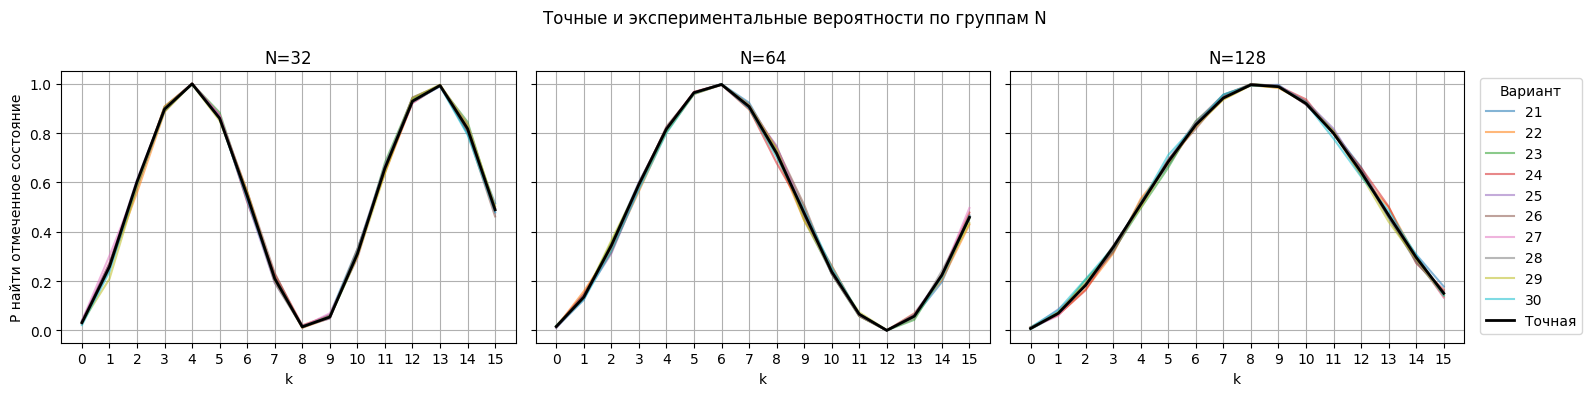

In [8]:
variant_states = {
    1: "01010", 2: "10101", 3: "11001", 4: "00110", 5: "11100",
    6: "00011", 7: "10010", 8: "01101", 9: "10110", 10: "01001",
    11: "001101", 12: "110010", 13: "101010", 14: "010101", 15: "111000",
    16: "000111", 17: "100110", 18: "011001", 19: "110100", 20: "001011",
    21: "0101010", 22: "1010101", 23: "1100110", 24: "0011001",
    25: "1111000", 26: "0000111", 27: "1001011", 28: "0110100",
    29: "1011010", 30: "0100101",
}

variant_circuits = []
variant_metadata = []
for variant, marked in variant_states.items():
    n = len(marked)
    exact_curve = [
        exact_marked_probability(n, marked, k) for k in k_values
    ]
    start = len(variant_circuits)
    for k in k_values:
        variant_circuits.append(
            build_grover_circuit(n, marked, k, measured=True)
        )
    variant_metadata.append(
        {
            "variant": variant,
            "n": n,
            "marked": marked,
            "exact": exact_curve,
            "start": start,
        }
    )

variant_result = AerSimulator().run(
    variant_circuits, shots=1024, seed_simulator=2026
).result()
variant_rows = []
for item in variant_metadata:
    experimental = [
        variant_result.get_counts(item["start"] + k).get(item["marked"], 0) / 1024
        for k in k_values
    ]
    item["experimental"] = experimental
    n = item["n"]
    exact = item["exact"]
    theoretical_k = math.floor(math.pi / 4 * math.sqrt(1 << n))
    exact_k = max(k_values, key=exact.__getitem__)
    experimental_k = max(k_values, key=experimental.__getitem__)
    variant_rows.append(
        (
            item["variant"],
            1 << n,
            item["marked"],
            theoretical_k,
            exact_k,
            experimental_k,
            max(exact),
        )
    )

print_table(
    ("Вариант", "N", "|w>", "k теор.", "k точн.", "k эксп.", "max P точн."),
    [row for row in variant_rows if row[0] == 7],
)

group_spread_rows = []
for n in (5, 6, 7):
    group = [item for item in variant_metadata if item["n"] == n]
    experimental_optima = [
        max(k_values, key=item["experimental"].__getitem__) for item in group
    ]
    group_spread_rows.append(
        (
            1 << n,
            min(experimental_optima),
            max(experimental_optima),
            sorted(set(experimental_optima)),
        )
    )
print_table(
    ("N", "min k эксп.", "max k эксп.", "Различные k эксп."),
    group_spread_rows,
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for axis, n in zip(axes, (5, 6, 7)):
    group = [item for item in variant_metadata if item["n"] == n]
    for item in group:
        axis.plot(
            k_values,
            item["experimental"],
            alpha=0.55,
            label="{}".format(item["variant"]),
        )
    axis.plot(
        k_values,
        group[0]["exact"],
        color="black",
        linewidth=2,
        label="Точная",
    )
    axis.set_title("N={}".format(1 << n))
    axis.set_xlabel("k")
    axis.set_xticks(k_values)
    axis.grid(True)
axes[0].set_ylabel("P найти отмеченное состояние")
axes[-1].legend(title="Вариант", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Точные и экспериментальные вероятности по группам N")
plt.tight_layout()
plt.show()

selected_variant_row = next(row for row in variant_rows if row[0] == 7)
assert selected_variant_row[1:3] == (32, "10010")



Точный оптимум зависит от размера пространства `N`, но не от конкретной
метки: все отмеченные состояния одного размера симметричны. Экспериментальные
оценки могут различаться из-за конечных 1024 shots; в группе `N=128`
соседние `k=8` и `k=9` имеют близкие вероятности.




### Шум для варианта 1 из задания 7

В соответствии с условием моделируется двухкубитный деполяризующий шум
только на CX при `p2=0.005` и `p2=0.02`. Перед запуском схемы раскладываются
в базис симулятора, поэтому многоуправляемые операции также дают шумные CX.
В этом подпункте условие отдельно задаёт вариант 1.



p2    | k максимума | Максимальная экспериментальная P
------+-------------+---------------------------------
0.005 | 3           | 0.37890625                      
0.02  | 1           | 0.1103515625                    


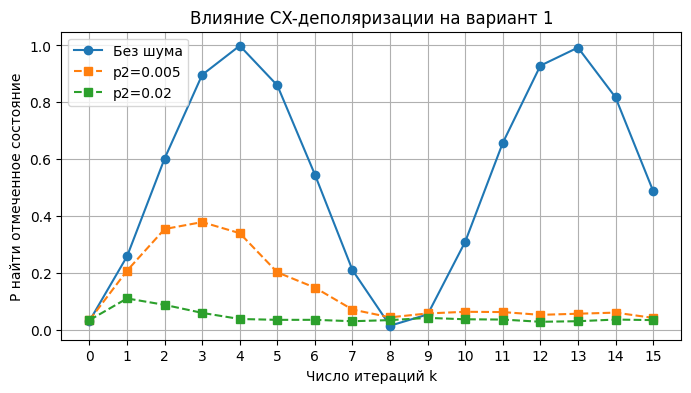

In [9]:
variant_1_marked = variant_states[1]
noise_grover_curves = {}
for p2 in (0.005, 0.02):
    circuits = [
        build_grover_circuit(5, variant_1_marked, k, measured=True)
        for k in k_values
    ]
    transpiled = transpile(
        circuits, basis_gates=["u", "cx"], optimization_level=0
    )
    assert all("ccx" not in circuit.count_ops() for circuit in transpiled)
    noise = NoiseModel()
    noise.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    simulator = AerSimulator(noise_model=noise)
    result = simulator.run(
        transpiled, shots=1024, seed_simulator=2026
    ).result()
    noise_grover_curves[p2] = [
        result.get_counts(k).get(variant_1_marked, 0) / 1024
        for k in k_values
    ]

noiseless_variant_1 = [
    exact_marked_probability(5, variant_1_marked, k) for k in k_values
]
print_table(
    ("p2", "k максимума", "Максимальная экспериментальная P"),
    [
        (
            p2,
            max(k_values, key=curve.__getitem__),
            max(curve),
        )
        for p2, curve in noise_grover_curves.items()
    ],
)
plt.figure(figsize=(8, 4))
plt.plot(k_values, noiseless_variant_1, "o-", label="Без шума")
for p2, curve in noise_grover_curves.items():
    plt.plot(k_values, curve, "s--", label="p2={}".format(p2))
plt.xlabel("Число итераций k")
plt.ylabel("P найти отмеченное состояние")
plt.xticks(k_values)
plt.grid(True)
plt.legend()
plt.title("Влияние CX-деполяризации на вариант 1")
plt.show()



С ростом двухкубитного шума уменьшаются максимум вероятности и выгодное
число итераций: каждый шаг Гровера добавляет новые CX после разложения
многоуправляемых вентилей. Поэтому большая глубина означает больше
возможностей для накопления ошибок.
